# Exploratory Data Analysis

This includes:
- Analyzing the distribution of the data.
- Identifying patterns and relationships between different variables.
- Checking for outliers and missing values to assess data quality.

## Data Collection

In [ ]:
import pandas as pd

DATA = "data/openData-master/canadian-electoral-reform"

comments = pd.read_csv(f"{DATA}/comments.csv")                  
votes = pd.read_csv(f"{DATA}/votes.csv")                       
participants = pd.read_csv(f"{DATA}/participants-votes.csv")   

print(comments.shape, votes.shape, participants.shape)

(174, 8) (12018, 5) (448, 180)


In [25]:
comments.head()

,timestamp,datetime,comment-id,author-id,agrees,disagrees,moderated,comment-body
0,1483908221702,Mon Jan 09 03:43:41 WIB 2017,161,282,5,4,1,MMP is simpler to explain than STV.
1,1483404737048,Tue Jan 03 07:52:17 WIB 2017,159,282,16,2,1,The Liberal party no longer supports meaningful electoral reform because they now have 55% of the seats with only 40% of the vote.
2,1483039164411,Fri Dec 30 02:19:24 WIB 2016,152,282,13,1,1,I have voted for a third-party candidate in a federal election.
3,1483026893056,Thu Dec 29 22:54:53 WIB 2016,148,282,17,1,1,I do not want my preferred party to have greater-than-proportional representation in parliament.
4,1482880437004,Wed Dec 28 06:13:57 WIB 2016,136,252,22,2,1,"Politically similar parties are pressured to merge by FPTP to gain proportional seats, such as the Conservative merger in 2003."


In [3]:
votes.head()

,timestamp,datetime,comment-id,voter-id,vote
0,1481275539794,Fri Dec 09 16:25:39 WIB 2016,0,0,0
1,1481313358937,Sat Dec 10 02:55:58 WIB 2016,0,3,1
2,1481315180458,Sat Dec 10 03:26:20 WIB 2016,0,4,1
3,1481318450219,Sat Dec 10 04:20:50 WIB 2016,0,7,1
4,1481321986609,Sat Dec 10 05:19:46 WIB 2016,0,9,1


**Rappel des variables :** `comment-id` identifiant de la proposition, `author-id` identifiant de son auteur, `agrees` et `disagrees` compteurs bruts fournis par Polis, `vote` valeur d'un vote individuel.

**Insight :**
- `comments.csv` est la table des propositions : identifiant, auteur, texte, compteurs d'accords et de désaccords.
- `votes.csv` est le format long : `vote` vaut **1 pour, -1 contre, 0 passe**.
- Un couple (citoyen, proposition) absent signifie non vue, ce qui n'est pas un 0.

## Data Analysis

In [4]:
print(f"{comments.shape[0]} proposals and {comments.shape[1]} columns")
comments.info()

174 proposals and 8 columns
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 174 entries, 0 to 173
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   timestamp     174 non-null    int64 
 1   datetime      174 non-null    object
 2   comment-id    174 non-null    int64 
 3   author-id     174 non-null    int64 
 4   agrees        174 non-null    int64 
 5   disagrees     174 non-null    int64 
 6   moderated     174 non-null    int64 
 7   comment-body  174 non-null    object
dtypes: int64(6), object(2)
memory usage: 11.0+ KB


In [5]:
print("Missing values per column:")
comments.isnull().sum()

Missing values per column:


timestamp       0
datetime        0
comment-id      0
author-id       0
agrees          0
disagrees       0
moderated       0
comment-body    0
dtype: int64

In [6]:
print(f"Number of different values per column\n{comments.nunique()}")
comments.describe()

Number of different values per column
timestamp       174
datetime        174
comment-id      174
author-id        23
agrees           84
disagrees        53
moderated         2
comment-body    174
dtype: int64


,timestamp,comment-id,author-id,agrees,disagrees,moderated
count,1.740000e+02,174.000000,174.000000,174.000000,174.000000,174.000000
mean,1.482127e+12,86.500000,116.568966,41.551724,16.442529,0.747126
std,1.009190e+09,50.373604,125.286370,36.706541,22.195782,0.666600
min,1.481276e+12,0.000000,0.000000,0.000000,0.000000,-1.000000
25%,1.481346e+12,43.250000,0.000000,11.000000,2.000000,1.000000
50%,1.481574e+12,86.500000,23.000000,27.000000,10.000000,1.000000
75%,1.482623e+12,129.750000,252.000000,75.000000,20.000000,1.000000
max,1.486447e+12,173.000000,365.000000,126.000000,117.000000,1.000000


**Rappel des variables :** `moderated` statut de modération (1 conservée, -1 retirée), `author-id` identifiant de l'auteur, `agrees` et `disagrees` compteurs bruts de votes pour et contre.

**Insight :**
- Aucune valeur manquante, mais `moderated` ne prend que deux valeurs : 1 (conservée) et -1 (retirée).
- Seulement 23 auteurs distincts pour 174 propositions : une poignée de personnes en a écrit la majorité.
- `agrees` et `disagrees` varient énormément, parce que les propositions sont arrivées à des dates différentes.

In [7]:
# Proposals removed by moderation: they were never submitted to the voters
comments["moderated"].value_counts()

moderated
 1    152
-1     22
Name: count, dtype: int64

In [8]:
comments[comments["moderated"] == -1][["comment-id", "agrees", "disagrees", "comment-body"]].head(10)

,comment-id,agrees,disagrees,comment-body
43,34,1,0,Something like 30 seats in Parliament allocate...
44,33,1,0,I would like a system reflecting the percentag...
45,35,1,0,I would then roll back the growth in the numbe...
55,50,1,0,All citizens deserve equal and effective votes.
58,47,1,0,Most countries which use proportional represen...
59,49,1,0,"The more seats that a party has in Parliament,..."
62,64,1,0,FPTP may seem like a simple voting system but ...
63,63,1,0,Policies are neither efficient nor effective i...
71,59,1,0,Both Conservative voters in the Atlantic and L...
75,55,1,0,Ranked ballots added to a winner-take-all voti...


**Rappel des variables :** `moderated` vaut -1 pour une proposition retirée par la modération, donc jamais soumise au vote des citoyens.

**Insight :**
- 22 propositions ont été retirées par la modération, et elles ne portent presque aucun vote (celui de leur auteur).
- Plusieurs ont été republiées par un autre auteur avec une légère reformulation, ce qui crée des quasi-doublons dans le corpus. Les écarter est le choix par défaut le plus sûr.

In [9]:
# Keep only the proposals that actually reached the voters
comments = comments[comments["moderated"] == 1]
print(f"{len(comments)} proposals kept")

152 proposals kept


### Build one table per proposal

In [10]:
# A citizen can vote several times on the same proposal (revisions, double clicks):
# keep the last vote only.
print("raw vote events:", len(votes))
votes = votes.sort_values("timestamp").drop_duplicates(["voter-id", "comment-id"], keep="last")
print("after deduplication:", len(votes))

# Polis records an automatic agree when the author creates a proposal: drop it.
authors = comments.set_index("comment-id")["author-id"]
votes = votes[votes["voter-id"] != votes["comment-id"].map(authors)]
print("after removing author self-votes:", len(votes))

raw vote events: 12018
after deduplication: 11950
after removing author self-votes: 11798


In [11]:
agg = votes.groupby("comment-id")["vote"].agg(
    n_seen="size",
    n_agree=lambda v: (v == 1).sum(),
    n_disagree=lambda v: (v == -1).sum(),
    n_pass=lambda v: (v == 0).sum(),
)

df = comments.set_index("comment-id").join(agg)
df["support"] = df["n_agree"] / df["n_seen"]           # share of those who saw it
df["net_agreement"] = (df["n_agree"] - df["n_disagree"]) / df["n_seen"]
df["n_words"] = df["comment-body"].str.split().str.len()

df = df[["author-id", "n_words", "n_seen", "n_agree", "n_disagree", "n_pass",
         "support", "net_agreement", "comment-body"]]
df.head()

,author-id,n_words,n_seen,n_agree,n_disagree,n_pass,support,net_agreement,comment-body
comment-id,,,,,,,,,
161,282,7,16,4,4,8,0.250000,0.000000,MMP is simpler to explain than STV.
159,282,23,20,13,2,5,0.650000,0.550000,The Liberal party no longer supports meaningfu...
152,282,11,16,12,1,3,0.750000,0.687500,I have voted for a third-party candidate in a ...
148,282,13,22,16,1,5,0.727273,0.681818,I do not want my preferred party to have great...
136,252,20,28,21,2,5,0.750000,0.678571,Politically similar parties are pressured to m...


In [12]:
print("\nSummary Statistics:")
df.describe()


Summary Statistics:


,author-id,n_words,n_seen,n_agree,n_disagree,n_pass,support,net_agreement
count,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000
mean,125.611842,14.717105,76.993421,46.375000,18.526316,12.092105,0.597611,0.370421
std,128.991352,5.645625,47.872416,35.839564,22.752031,9.915775,0.233080,0.426467
min,0.000000,3.000000,9.000000,2.000000,0.000000,0.000000,0.058824,-0.825758
25%,0.000000,10.000000,22.750000,15.000000,3.750000,4.000000,0.435702,0.108796
50%,56.000000,15.000000,86.500000,32.000000,12.500000,9.500000,0.645269,0.507722
75%,252.000000,19.250000,123.250000,77.250000,22.000000,18.000000,0.771703,0.688702
max,365.000000,27.000000,147.000000,126.000000,117.000000,55.000000,1.000000,1.000000


**Rappel des variables :** `n_seen` nombre de citoyens ayant vu la proposition (et donc voté dessus, quel que soit le vote), `n_words` nombre de mots de son texte, `support` = `n_agree` / `n_seen`, soit la part de soutien parmi ceux qui l'ont vue.

**Insight :**
- `n_seen` va de 9 à 147 : l'exposition est très inégale d'une proposition à l'autre.
- Les propositions sont courtes (médiane 15 mots, maximum 27), bien plus courtes qu'un projet rédigé.
- `support` a une médiane autour de 0,65 mais ses extrêmes sont portés par des propositions que presque personne n'a vues : un classement brut sur `support` n'a donc pas de sens tel quel.

In [13]:
# Check for duplicate proposal texts
print("\nDuplicate proposal texts:")
df[df["comment-body"].duplicated(keep=False)]


Duplicate proposal texts:


,author-id,n_words,n_seen,n_agree,n_disagree,n_pass,support,net_agreement,comment-body
comment-id,,,,,,,,,


**Rappel des variables :** `comment-body` est le texte brut de la proposition, le seul champ sur lequel porte ce test de doublons.

**Insight :**
- Aucun doublon exact après modération, mais des quasi-doublons subsistent (par exemple « I like to educate myself on my local candidates » face à « I often educate myself... »).
- La comparaison exacte ne suffit pas : un regroupement sémantique sera nécessaire.


Histograms of numerical features:


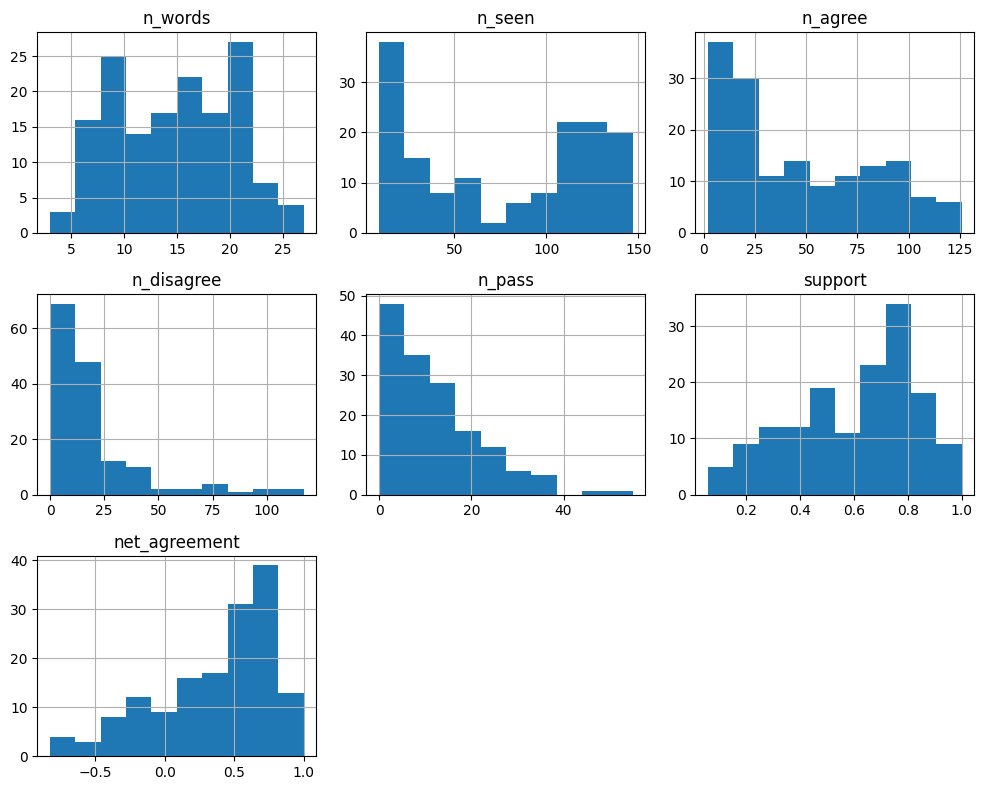

In [14]:
import matplotlib.pyplot as plt

# Histograms for all numerical features
print("\nHistograms of numerical features:")
df.drop(columns=["author-id", "comment-body"]).hist(figsize=(10, 8))
plt.tight_layout()
plt.show()

**Rappel des variables :** `n_words` nombre de mots, `n_seen` nombre de citoyens ayant vu la proposition, `n_agree` et `n_disagree` votes pour et contre, `support` = `n_agree` / `n_seen`, `net_agreement` = (`n_agree` - `n_disagree`) / `n_seen`.

**Insight :**
1. `n_words` : à peu près symétrique autour de 15 mots, sans queue longue.
2. `n_seen` : nettement bimodal. Les premières propositions ont été vues par environ 130 citoyens, les dernières par une dizaine. C'est un artefact de la date d'arrivée, pas de la qualité.
3. `n_agree` et `n_disagree` : étalés vers la droite, dominés par ces mêmes propositions précoces.
4. `support` : concentré entre 0,4 et 0,8, avec une poignée de propositions à 1,0 qui ont toutes été vues par dix personnes ou moins.
5. `net_agreement` : réparti sur tout l'intervalle [-1, 1], donc la consultation contient du désaccord réel et pas seulement du consensus.


Box plots to check for outliers:


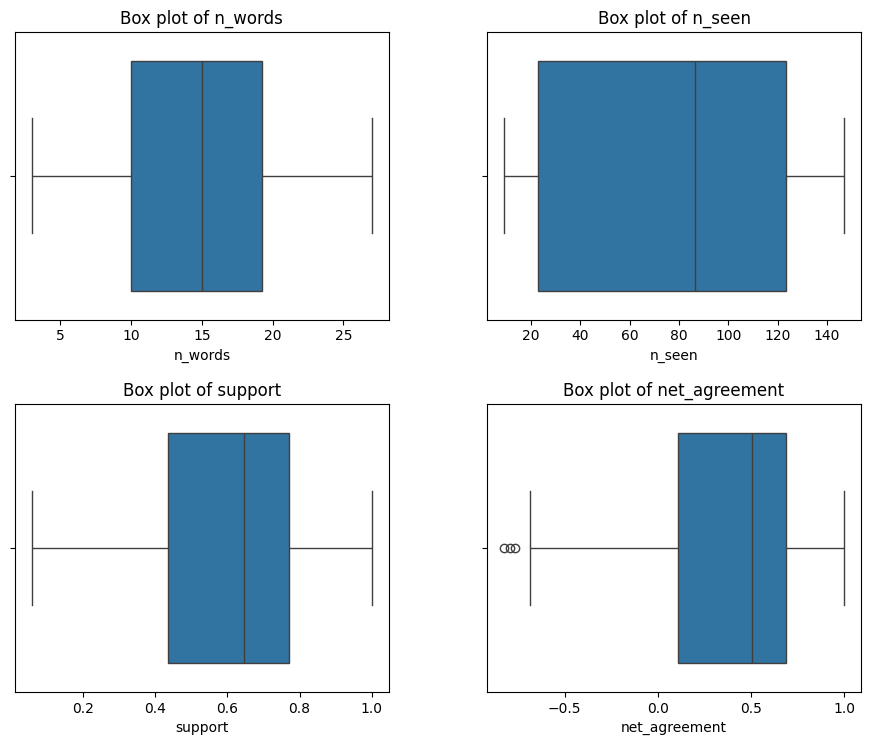

In [15]:
import seaborn as sns
import numpy as np

# Box plots for numerical variables to check outliers
print("\nBox plots to check for outliers:")
numeric_cols = ["n_words", "n_seen", "support", "net_agreement"]

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 8))
fig.tight_layout(pad=4.0)

for i, col in enumerate(numeric_cols):
    sns.boxplot(x=df[col], ax=axes[i // 2, i % 2])
    axes[i // 2, i % 2].set_title(f"Box plot of {col}")

plt.show()

**Rappel des variables :** `n_words` nombre de mots, `n_seen` nombre de citoyens ayant vu la proposition, `support` part de soutien parmi eux, `net_agreement` solde entre votes pour et contre, de -1 à 1.

**Insight :**
1. `n_words` : quelques propositions longues, rien d'extrême.
2. `n_seen` : aucune valeur aberrante au sens statistique, mais un intervalle interquartile très large. La variable est bimodale plutôt que bruitée.
3. `support` : les valeurs basses isolées sont des propositions vues et rejetées.
4. `net_agreement` : c'est la queue négative qui est intéressante. Ce sont ces propositions qu'un résumé a tendance à écarter, et c'est précisément ce que la métrique de préservation du désaccord pénalise.

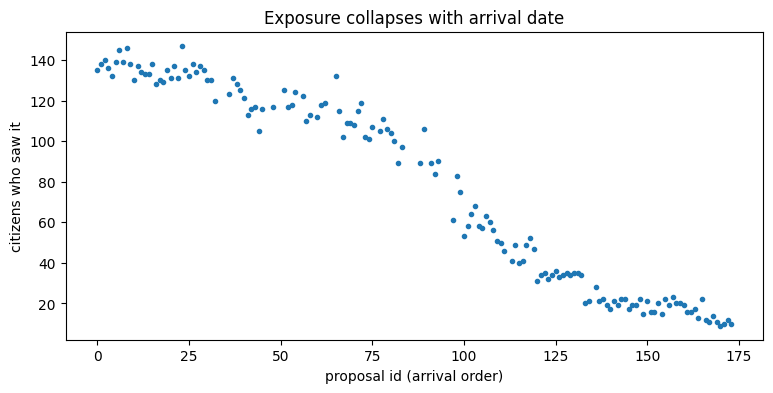

In [16]:
# Exposure against arrival order
plt.figure(figsize=(9, 4))
plt.plot(df.index, df["n_seen"], ".")
plt.xlabel("proposal id (arrival order)")
plt.ylabel("citizens who saw it")
plt.title("Exposure collapses with arrival date")
plt.show()

**Rappel des variables :** `n_seen` nombre de citoyens ayant vu la proposition, tracé contre `comment-id`, qui suit l'ordre d'arrivée chronologique.

**Insight :**
- L'exposition décroît de façon quasi monotone avec l'identifiant de la proposition.
- Conséquence pour le pipeline : ne jamais normaliser le soutien sur le nombre total de participants, uniquement sur le nombre de citoyens qui ont réellement vu la proposition.

## Correlation Analysis

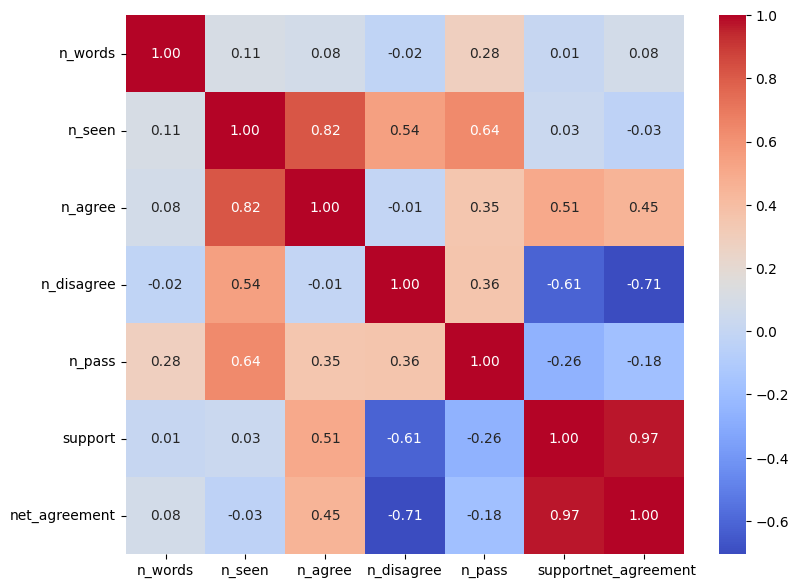

In [17]:
# comment-body is text, we remove it for the correlation matrix
corr_matrix = df.drop(columns=["comment-body", "author-id"]).corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

**Rappel des variables :** `n_seen` nombre de citoyens ayant vu la proposition, `n_agree` nombre de votes pour, `support` = `n_agree` / `n_seen`, `net_agreement` solde pour/contre normalisé sur `n_seen`, `n_words` longueur du texte.

**Insight :**
1. `n_seen` est quasi décorrélé de `support` (0,03) : être vue par beaucoup de citoyens ne rend pas une proposition plus populaire. Bonne nouvelle, le biais d'exposition ne contamine pas le signal de soutien lui-même.
2. `support` et `net_agreement` corrèlent à 0,97, donc ils classent les propositions presque à l'identique. Une des deux suffit.
3. `n_words` ne corrèle avec rien : la longueur ne porte aucune information sur le soutien.
4. `n_agree` corrèle fortement avec `n_seen` et non avec `support`, ce qui explique pourquoi les compteurs bruts ne doivent jamais servir de classement de popularité.

### Opinion groups

In [18]:
# participants-votes.csv adds the k-means group assignment computed by Polis
participants["group-id"].value_counts(dropna=False)

group-id
1.0    265
NaN    167
0.0     16
Name: count, dtype: int64

In [19]:
# Mean agreement per proposal, within each opinion group
meta = ["participant", "group-id", "n-comments", "n-votes", "n-agree", "n-disagree"]
matrix = participants.set_index("participant").drop(columns=meta[1:])
matrix.columns = matrix.columns.astype(int)

groups = participants.set_index("participant")["group-id"].dropna()
agree_by_group = pd.DataFrame({
    f"group_{int(g)}": (matrix.loc[idx] == 1).sum() / matrix.loc[idx].notna().sum()
    for g, idx in groups.groupby(groups).groups.items()
})
agree_by_group = agree_by_group.reindex(df.index).dropna()
agree_by_group["divisiveness"] = agree_by_group.max(axis=1) - agree_by_group.min(axis=1)
agree_by_group.sort_values("divisiveness", ascending=False).head(10)

,group_0,group_1,divisiveness
comment-id,,,
44,0.000000,0.855556,0.855556
22,0.076923,0.914530,0.837607
29,0.066667,0.896552,0.829885
128,0.000000,0.794118,0.794118
13,0.785714,0.008696,0.777019
43,0.076923,0.841584,0.764661
14,0.833333,0.093220,0.740113
56,0.000000,0.733945,0.733945
127,0.000000,0.676471,0.676471


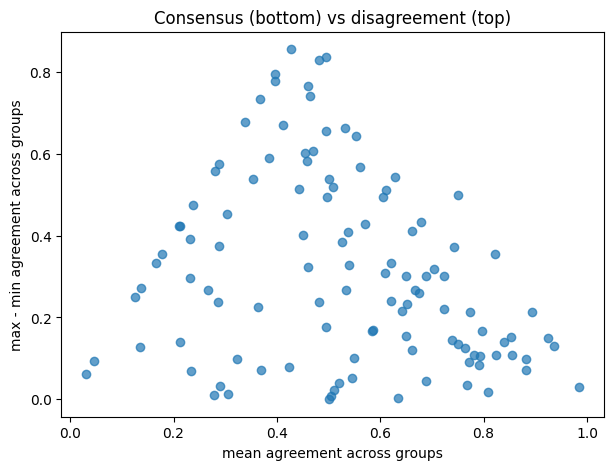

In [20]:
plt.figure(figsize=(7, 5))
plt.scatter(agree_by_group.filter(like="group_").mean(axis=1),
            agree_by_group["divisiveness"], alpha=0.7)
plt.xlabel("mean agreement across groups")
plt.ylabel("max - min agreement across groups")
plt.title("Consensus (bottom) vs disagreement (top)")
plt.show()

**Rappel des variables :** `group-id` groupe d'opinion attribué par le k-means de Polis, `group_0` et `group_1` taux d'accord moyen d'une proposition à l'intérieur de chaque groupe, `divisiveness` écart entre le taux d'accord le plus élevé et le plus faible entre groupes.

**Insight :**
- Deux groupes d'opinion seulement (16 et 265 citoyens), plus 167 participants ayant trop peu voté pour être assignés.
- Les propositions en haut du graphique séparent les deux groupes presque complètement (jusqu'à 0,86 d'écart de taux d'accord, et dans les deux sens). Un résumé qui ne garde que le bas du graphique obtient un bon score de fidélité et un mauvais score de préservation du désaccord. Cet arbitrage est le cœur de la shared task.
- À noter : `group-id` est produit par le clustering de Polis, ce n'est pas une donnée brute. La shared task ne le fournira pas, donc rien dans le pipeline ne doit en dépendre.

## Automated EDA Report with Pandas Profiling

In [21]:
#!pip install ydata-profiling
from ydata_profiling import ProfileReport

# Generate the Pandas Profiling Report
profile = ProfileReport(df.drop(columns=["comment-body"]),
                        title="Pandas Profiling Report - Citizen Consultation",
                        explorative=True)

# Save the report to an HTML file (optional)
profile.to_file("consultation_data_report.html")

#profile.to_notebook_iframe()

/Users/popov/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 8/8 [00:00<00:00, 26588.30it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]